# **MML23 Image Dataset: Data Analysis**

This notebook provides an initial data analysis of the local MML23 image dataset.

The local folder used here is named MML23. The analysis treats it as a supervised image classification dataset where each class is represented by one directory of TIFF images.

The goal is to understand the image data before training: number of images, class balance, label consistency, image format, visual appearance, and simple pixel-level statistics.


The notebook reads the dataset location from the project `.env` file, using the variable `MML23_DATA_DIR`. 


In [1]:
import os
import re
import math
import time
import warnings
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("default")

sns.set_theme(context="notebook", style="whitegrid", font_scale=1.0)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
})

In [2]:
DATASET_ENV_VAR = "MML23_DATA_DIR"
ENV_FILE = Path(".env")


def read_env_file(env_file):
    if not env_file.exists():
        raise FileNotFoundError("The project .env file was not found.")

    values = {}
    for line in env_file.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        key, value = line.split("=", 1)
        values[key.strip()] = value.strip().strip('"').strip("'")
    return values


env_values = read_env_file(ENV_FILE)
dataset_value = env_values.get(DATASET_ENV_VAR)
if not dataset_value:
    raise EnvironmentError(f"Set {DATASET_ENV_VAR} in the project .env file before running this notebook.")

dataset_root = Path(dataset_value).expanduser().resolve()
if not dataset_root.exists() or not dataset_root.is_dir():
    raise FileNotFoundError(f"The directory configured in {DATASET_ENV_VAR} does not exist or is not a directory.")

print(f"Dataset configuration: {DATASET_ENV_VAR}")
print(f"Dataset folder name: {dataset_root.name}")


Dataset configuration: MML23_DATA_DIR
Dataset folder name: MML23


The local dataset is represented as class directories containing image files. The directory name is used as the class label.


In [3]:
IMAGE_EXTENSIONS = {".tif"}

rows = []
class_dirs = sorted([path for path in dataset_root.iterdir() if path.is_dir()], key=lambda p: p.name.lower())

for class_dir in class_dirs:
    label = class_dir.name
    image_files = sorted(
        [path for path in class_dir.iterdir() if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS],
        key=lambda p: p.name.lower(),
    )
    for image_path in image_files:
        match = re.fullmatch(r"(?P<name_label>.+)_(?P<index>[0-9]+)", image_path.stem)
        rows.append({
            "relative_path": f"{label}/{image_path.name}",
            "label": label,
            "filename": image_path.name,
            "name_label": match.group("name_label") if match else np.nan,
            "index": int(match.group("index")) if match else np.nan,
        })

image_manifest = pd.DataFrame(rows)
if image_manifest.empty:
    raise ValueError("No TIFF images were found in class directories.")

print(f"Images: {len(image_manifest):,}")
print(f"Classes: {image_manifest['label'].nunique():,}")
display(image_manifest.head())


Images: 41,621
Classes: 18


,relative_path,label,filename,name_label,index
0,basophil/basophil_0001.TIF,basophil,basophil_0001.TIF,basophil,1
1,basophil/basophil_0002.TIF,basophil,basophil_0002.TIF,basophil,2
2,basophil/basophil_0003.TIF,basophil,basophil_0003.TIF,basophil,3
3,basophil/basophil_0004.TIF,basophil,basophil_0004.TIF,basophil,4
4,basophil/basophil_0005.TIF,basophil,basophil_0005.TIF,basophil,5


## Class Balance

Class balance is one of the first practical questions for this dataset. Large class imbalance affects training, validation, and interpretation of aggregate metrics.


In [4]:
class_counts = (
    image_manifest
    .groupby("label", as_index=False)
    .agg(images=("relative_path", "count"))
    .sort_values("images", ascending=False)
)
class_counts["fraction"] = class_counts["images"] / class_counts["images"].sum()
class_counts["percent"] = 100 * class_counts["fraction"]

largest = class_counts.iloc[0]
smallest = class_counts.iloc[-1]
imbalance_ratio = largest["images"] / smallest["images"]

print(f"Most represented class: {largest['label']} ({int(largest['images']):,} images)")
print(f"Least represented class: {smallest['label']} ({int(smallest['images']):,} images)")
print(f"Largest to smallest class ratio: {imbalance_ratio:.1f}")
display(class_counts)


Most represented class: myeloblast (8,606 images)
Least represented class: lymphocyte_reactive (33 images)
Largest to smallest class ratio: 260.8


,label,images,fraction,percent
9,myeloblast,8606,0.206771,20.677062
12,neutrophil_segmented,7170,0.172269,17.226881
3,lymphocyte,5532,0.132914,13.291367
2,hairy_cell,3265,0.078446,7.844598
8,monocyte,2510,0.060306,6.030610
1,eosinophil,2448,0.058816,5.881646
13,normoblast,2071,0.049759,4.975854
16,promyelocyte_atypical,2033,0.048846,4.884553
4,lymphocyte_large_granular,1849,0.044425,4.442469
14,plasma_cell,1658,0.039836,3.983566


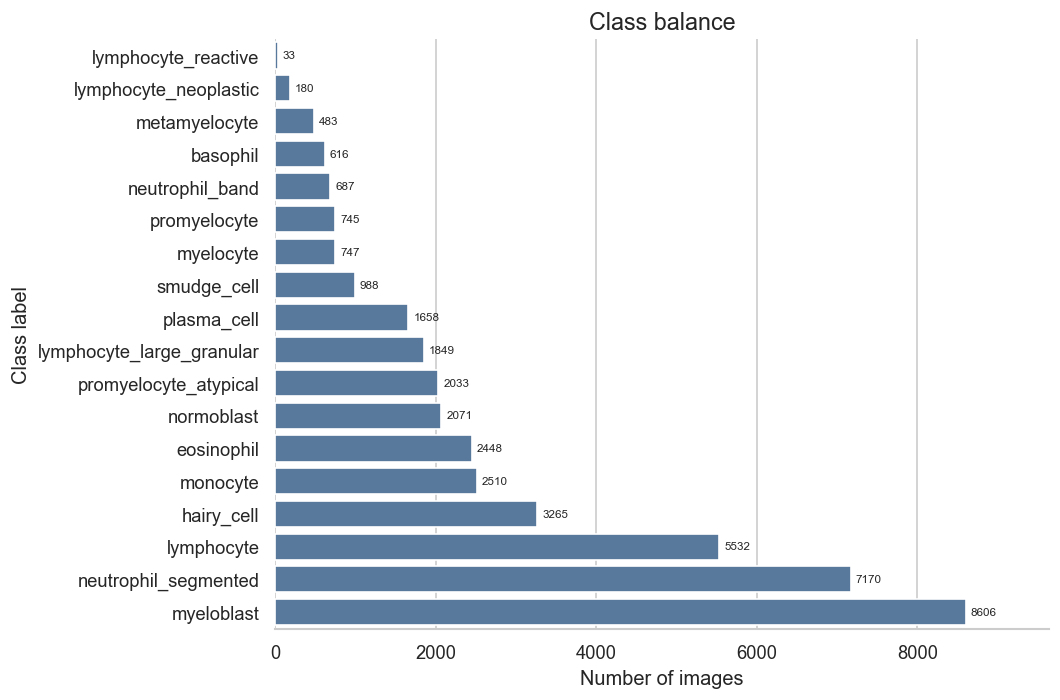

In [5]:
class_order = class_counts.sort_values("images", ascending=True)["label"].tolist()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=class_counts.sort_values("images", ascending=True), y="label", x="images", color="#4C78A8", ax=ax)
ax.set_title("Class balance")
ax.set_xlabel("Number of images")
ax.set_ylabel("Class label")
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=7)
ax.margins(x=0.12)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()



This section checks whether images can be opened and whether dimensions, channels, and frame counts are consistent. When `tifffile` is available, all TIFF headers are scanned. Otherwise a deterministic stratified sample is checked with Pillow to keep the notebook responsive.


In [9]:
def stratified_sample(df, n_per_label, seed=RANDOM_STATE):
    samples = []
    for _, group in df.groupby("label", sort=True):
        n = min(n_per_label, len(group))
        samples.append(group.sample(n=n, random_state=seed))
    return pd.concat(samples, ignore_index=True)


def parse_tiff_shape(shape):
    shape = tuple(shape)
    if len(shape) == 2:
        return shape[0], shape[1], 1
    if len(shape) == 3 and shape[-1] in {1, 3, 4}:
        return shape[0], shape[1], shape[-1]
    if len(shape) == 3 and shape[0] in {1, 3, 4}:
        return shape[1], shape[2], shape[0]
    return np.nan, np.nan, np.nan


tifffile_available = importlib.util.find_spec("tifffile") is not None
if tifffile_available:
    import tifffile
    header_source = image_manifest.copy()
    header_method = "all TIFF headers with tifffile"
else:
    header_source = stratified_sample(image_manifest, n_per_label=80)
    header_method = "stratified header sample with Pillow"

header_rows = []
header_errors = []
start = time.time()

for row in header_source.itertuples(index=False):
    image_path = dataset_root / row.relative_path
    try:
        if tifffile_available:
            with tifffile.TiffFile(image_path) as tif:
                series = tif.series[0]
                height, width, channels = parse_tiff_shape(series.shape)
                mode = ""
                dtype = str(series.dtype)
                frames = len(tif.pages)
        else:
            with Image.open(image_path) as img:
                width, height = img.size
                channels = len(img.getbands())
                mode = img.mode
                dtype = ""
                frames = getattr(img, "n_frames", 1)
        header_rows.append({
            "label": row.label,
            "relative_path": row.relative_path,
            "height": height,
            "width": width,
            "channels": channels,
            "mode": mode,
            "dtype": dtype,
            "frames": frames,
        })
    except Exception as exc:
        header_errors.append({"label": row.label, "relative_path": row.relative_path, "error": repr(exc)})

header_df = pd.DataFrame(header_rows)
header_error_df = pd.DataFrame(header_errors)

print(f"Header check method: {header_method}")
print(f"Images checked: {len(header_df):,}")
print(f"Read errors: {len(header_error_df):,}")
print(f"Elapsed seconds: {time.time() - start:.1f}")

format_summary = (
    header_df
    .groupby(["height", "width", "channels", "mode", "dtype", "frames"], dropna=False)
    .size()
    .rename("images")
    .reset_index()
    .sort_values("images", ascending=False)
)
display(format_summary)

if not header_error_df.empty:
    display(header_error_df.head(20))


Header check method: all TIFF headers with tifffile
Images checked: 41,621
Read errors: 0
Elapsed seconds: 495.8


,height,width,channels,mode,dtype,frames,images
0,288,288,3,,uint8,1,41621


## Representative Images

A small deterministic sample helps verify that files correspond to single-cell microscopy images and gives a first view of inter-class visual variability.


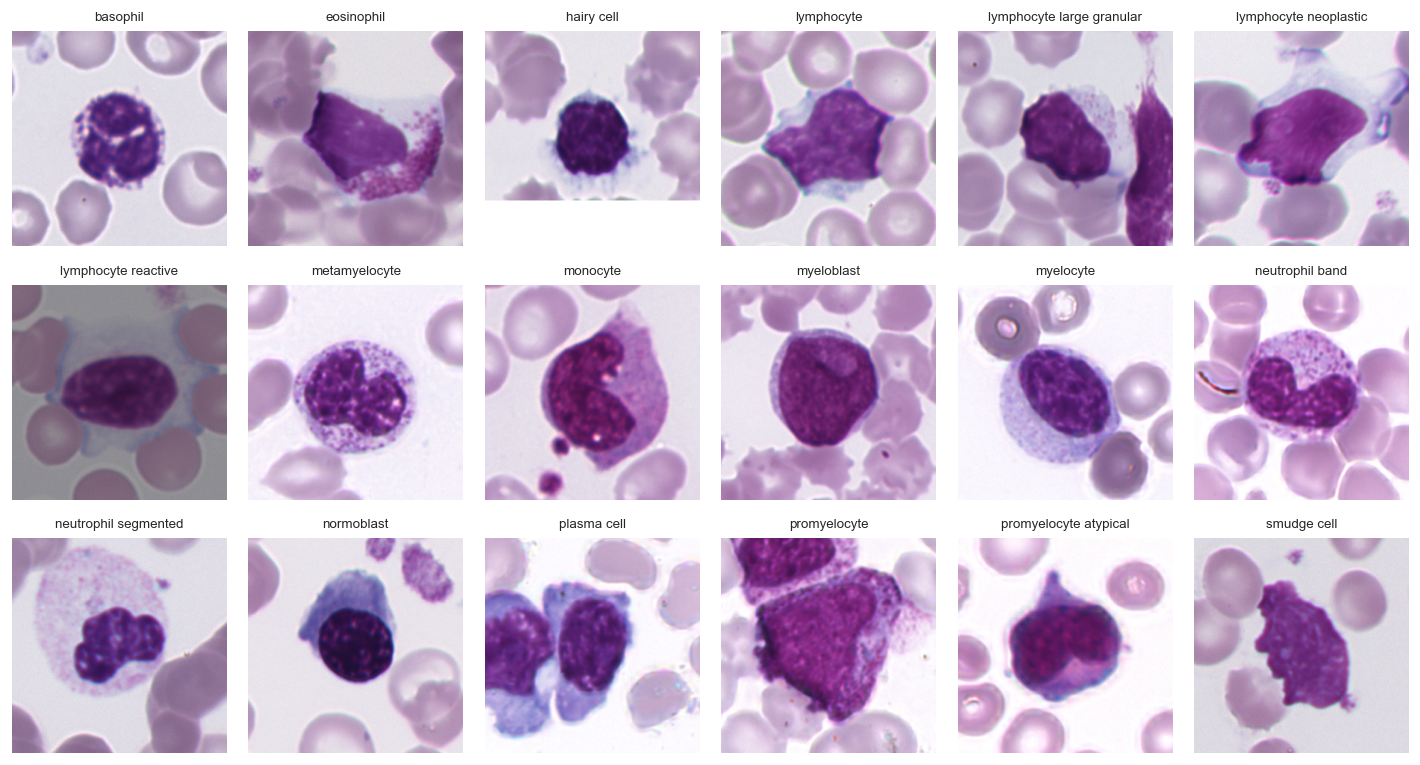

In [10]:
gallery_sample = stratified_sample(image_manifest, n_per_label=1).sort_values("label")
ncols = 6
nrows = math.ceil(len(gallery_sample) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 2.2 * nrows))
axes = np.asarray(axes).reshape(-1)

for ax, row in zip(axes, gallery_sample.itertuples(index=False)):
    with Image.open(dataset_root / row.relative_path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row.label.replace("_", " "), fontsize=8)
    ax.axis("off")

for ax in axes[len(gallery_sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Pixel-Level Descriptors

The next cells compute simple descriptors on a stratified sample: brightness, contrast, RGB channel means, saturation, edge strength, and file size. These descriptors are useful for quality control and for detecting acquisition differences. They are not morphological annotations.


In [12]:
FEATURE_SAMPLE_PER_CLASS = int(os.environ.get("MML23_FEATURE_SAMPLE_PER_CLASS", "120"))
feature_source = stratified_sample(image_manifest, n_per_label=FEATURE_SAMPLE_PER_CLASS)
print(f"Images sampled for pixel descriptors: {len(feature_source):,}")

feature_rows = []
for row in feature_source.itertuples(index=False):
    with Image.open(dataset_root / row.relative_path) as img:
        rgb = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

    gray = 0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1] + 0.114 * rgb[:, :, 2]
    gy, gx = np.gradient(gray)
    edge_strength = np.sqrt(gx * gx + gy * gy)
    saturation = rgb.max(axis=2) - rgb.min(axis=2)

    feature_rows.append({
        "relative_path": row.relative_path,
        "label": row.label,
        "mean_red": float(rgb[:, :, 0].mean()),
        "mean_green": float(rgb[:, :, 1].mean()),
        "mean_blue": float(rgb[:, :, 2].mean()),
        "mean_gray": float(gray.mean()),
        "std_gray": float(gray.std()),
        "p05_gray": float(np.quantile(gray, 0.05)),
        "p50_gray": float(np.quantile(gray, 0.50)),
        "p95_gray": float(np.quantile(gray, 0.95)),
        "dark_fraction": float((gray < 0.15).mean()),
        "bright_fraction": float((gray > 0.90).mean()),
        "mean_saturation": float(saturation.mean()),
        "mean_edge_strength": float(edge_strength.mean()),
    })

image_features = pd.DataFrame(feature_rows)
display(image_features.head())


Images sampled for pixel descriptors: 2,073


,relative_path,label,mean_red,mean_green,mean_blue,mean_gray,std_gray,p05_gray,p50_gray,p95_gray,dark_fraction,bright_fraction,mean_saturation,mean_edge_strength
0,basophil/basophil_0079.TIF,basophil,0.763365,0.709581,0.806422,0.736703,0.199842,0.242815,0.853404,0.909697,0.000000,0.072422,0.100601,0.017263
1,basophil/basophil_0209.TIF,basophil,0.767316,0.706615,0.808046,0.736328,0.214103,0.253557,0.874443,0.906137,0.000470,0.098235,0.106130,0.016500
2,basophil/basophil_0571.TIF,basophil,0.753989,0.678069,0.786698,0.713153,0.226654,0.228937,0.845196,0.906555,0.000772,0.101864,0.116131,0.014961
3,basophil/basophil_0182.TIF,basophil,0.708412,0.610502,0.744081,0.655005,0.212624,0.208155,0.682259,0.896101,0.005425,0.030876,0.136883,0.018791
4,basophil/basophil_0102.TIF,basophil,0.727593,0.661383,0.779236,0.694615,0.215095,0.246931,0.773771,0.895901,0.000482,0.040606,0.121249,0.017972


In [14]:
feature_summary = (
    image_features
    .groupby("label", as_index=False)
    .agg(
        sampled_images=("relative_path", "count"),
        mean_gray=("mean_gray", "mean"),
        std_gray=("std_gray", "mean"),
        mean_saturation=("mean_saturation", "mean"),
        mean_edge_strength=("mean_edge_strength", "mean"),
    )
    .sort_values("label")
)
display(feature_summary.round(4))


,label,sampled_images,mean_gray,std_gray,mean_saturation,mean_edge_strength
0,basophil,120,0.7069,0.2438,0.1228,0.0174
1,eosinophil,120,0.7546,0.2259,0.1338,0.0148
2,hairy_cell,120,0.7100,0.2248,0.1109,0.0130
3,lymphocyte,120,0.6945,0.2069,0.1204,0.0142
4,lymphocyte_large_granular,120,0.6901,0.2043,0.1200,0.0130
5,lymphocyte_neoplastic,120,0.6547,0.1862,0.1639,0.0141
6,lymphocyte_reactive,33,0.6622,0.1926,0.1296,0.0135
7,metamyelocyte,120,0.7599,0.2238,0.1306,0.0147
8,monocyte,120,0.6691,0.2142,0.1362,0.0148
9,myeloblast,120,0.6398,0.2377,0.1502,0.0149


c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


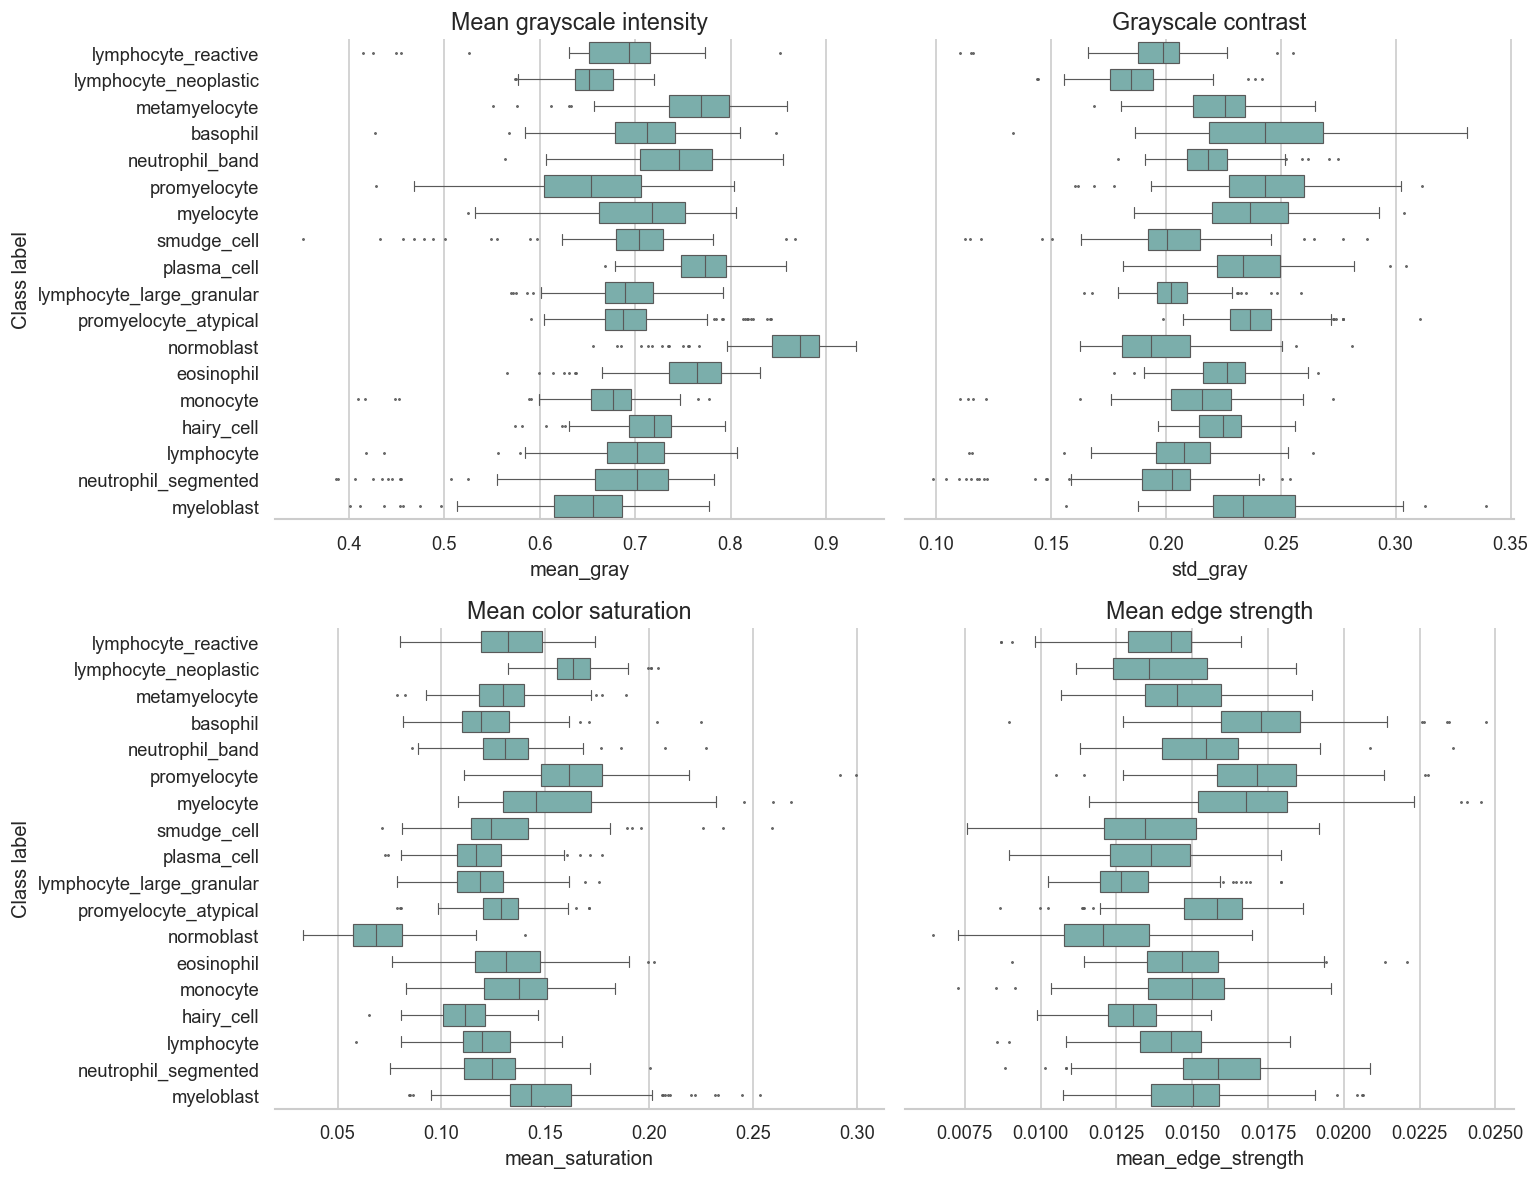

In [15]:
metrics = [
    ("mean_gray", "Mean grayscale intensity"),
    ("std_gray", "Grayscale contrast"),
    ("mean_saturation", "Mean color saturation"),
    ("mean_edge_strength", "Mean edge strength"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)
axes = axes.reshape(-1)

for ax, (metric, title) in zip(axes, metrics):
    sns.boxplot(
        data=image_features,
        y="label",
        x=metric,
        order=class_order,
        color="#72B7B2",
        fliersize=0.7,
        linewidth=0.7,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(metric)
    ax.set_ylabel("Class label" if ax is axes[0] or ax is axes[2] else "")

sns.despine(fig=fig, left=True)
plt.tight_layout()
plt.show()


c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\envs\secqdevops_env\Lib\site-packages\seaborn\categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


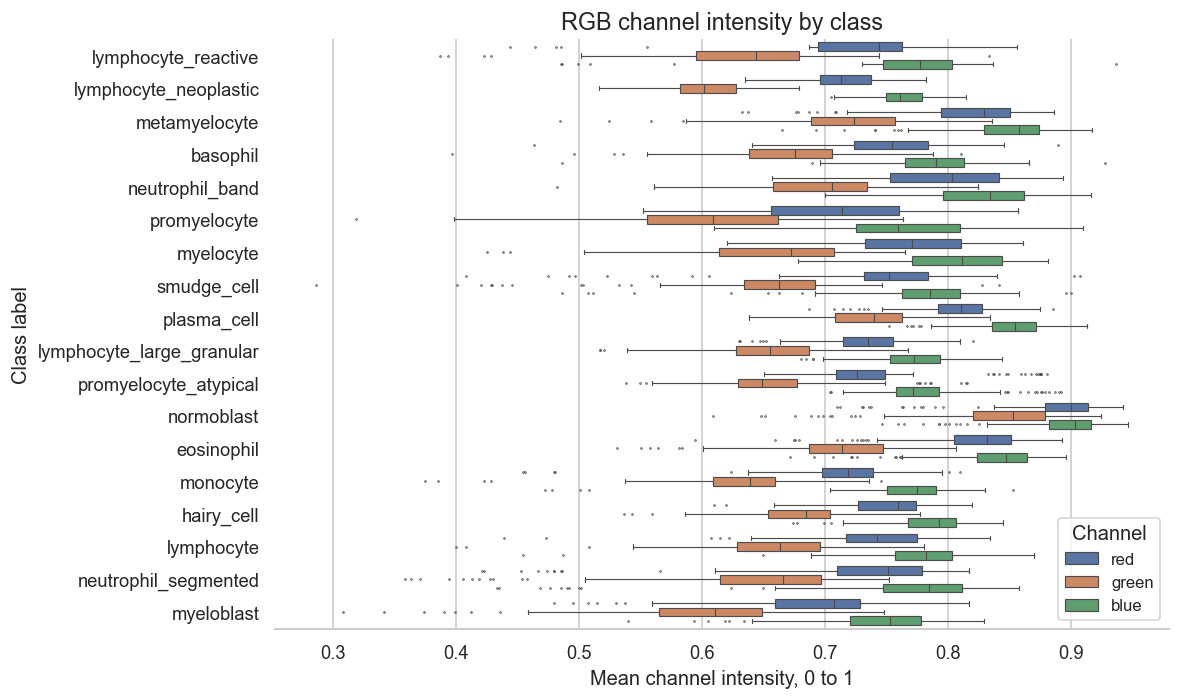

In [16]:
channel_long = image_features.melt(
    id_vars=["relative_path", "label"],
    value_vars=["mean_red", "mean_green", "mean_blue"],
    var_name="channel",
    value_name="mean_intensity",
)
channel_long["channel"] = channel_long["channel"].str.replace("mean_", "", regex=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=channel_long,
    y="label",
    x="mean_intensity",
    hue="channel",
    order=class_order,
    fliersize=0.5,
    linewidth=0.7,
    ax=ax,
)
ax.set_title("RGB channel intensity by class")
ax.set_xlabel("Mean channel intensity, 0 to 1")
ax.set_ylabel("Class label")
ax.legend(title="Channel", loc="lower right")
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()


## Visual Check of Descriptor Extremes

The following examples show images with extreme descriptor values in the sampled subset. This helps identify whether outliers look like plausible cells, staining variation, focus differences, or image artifacts.


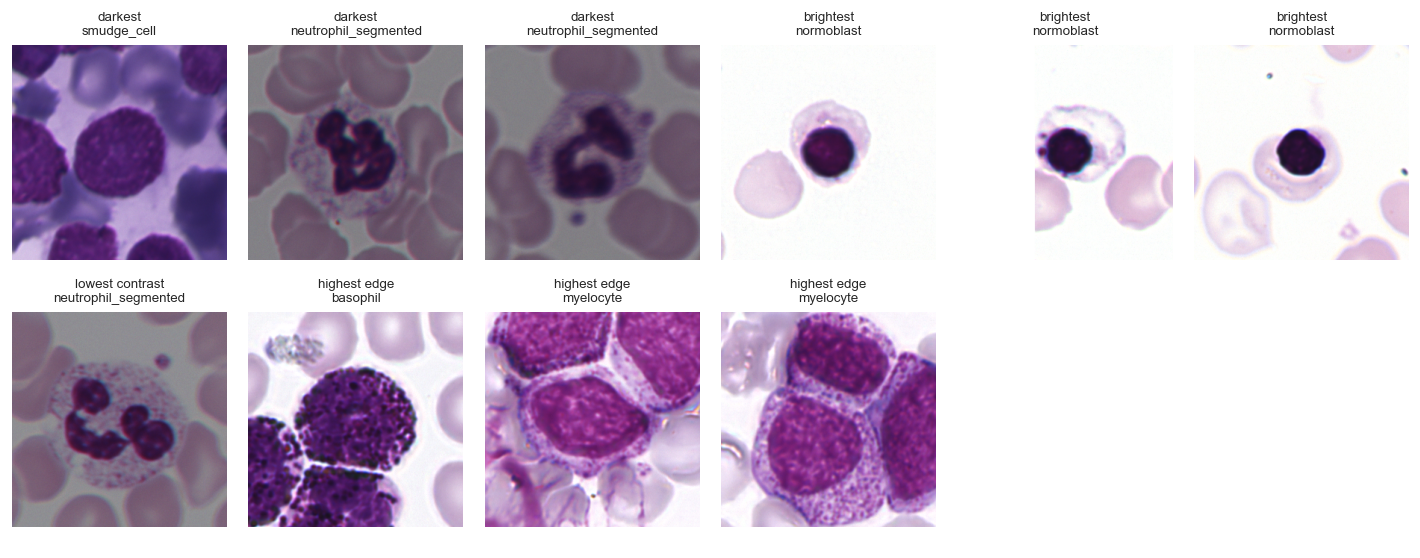

In [17]:
extreme_examples = pd.concat([
    image_features.nsmallest(3, "mean_gray").assign(selection="darkest"),
    image_features.nlargest(3, "mean_gray").assign(selection="brightest"),
    image_features.nsmallest(3, "std_gray").assign(selection="lowest contrast"),
    image_features.nlargest(3, "mean_edge_strength").assign(selection="highest edge"),
], ignore_index=True).drop_duplicates("relative_path")

ncols = 6
nrows = math.ceil(len(extreme_examples) / ncols)
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 2.4 * nrows))
axes = np.asarray(axes).reshape(-1)

for ax, row in zip(axes, extreme_examples.itertuples(index=False)):
    with Image.open(dataset_root / row.relative_path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{row.selection}\n{row.label}", fontsize=8)
    ax.axis("off")

for ax in axes[len(extreme_examples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Low-Dimensional View of Basic Image Descriptors

PCA is used here only as a compact visualization of simple image-level descriptors. It should be interpreted as a quality-control view, not as a model of cell identity.


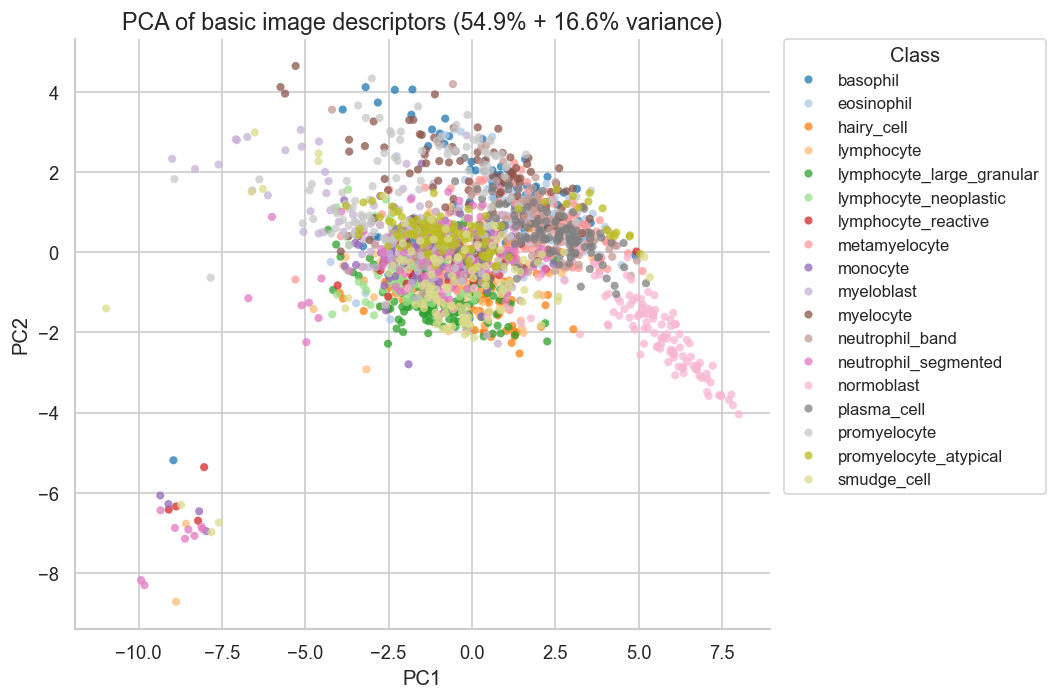

In [19]:
feature_columns = [
    "mean_red", "mean_green", "mean_blue",
    "mean_gray", "std_gray", "p05_gray", "p50_gray", "p95_gray",
    "dark_fraction", "bright_fraction", "mean_saturation", "mean_edge_strength",
]

X = image_features[feature_columns].replace([np.inf, -np.inf], np.nan).dropna()
labels_for_x = image_features.loc[X.index, "label"]

if len(X) >= 3 and labels_for_x.nunique() >= 2:
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pcs = pca.fit_transform(X_scaled)
    pca_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "label": labels_for_x.to_numpy()})

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="label",
        palette="tab20",
        s=24,
        alpha=0.75,
        linewidth=0,
        ax=ax,
    )
    ax.set_title(
        "PCA of basic image descriptors "
        f"({100 * pca.explained_variance_ratio_[0]:.1f}% + {100 * pca.explained_variance_ratio_[1]:.1f}% variance)"
    )
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough complete feature rows for PCA.")


## Conclusions

The MML23 is an image classification dataset: labels are encoded by class directories and each record is a TIFF image of one cell.

The main dataset-level issue to account for is class imbalance. Downstream experiments should use stratified splits, per-class metrics, and a training strategy that does not let large classes dominate the objective.

The pixel descriptors and PCA view provide an initial quality-control perspective. They can reveal brightness, staining, focus, or acquisition differences.
